In [10]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
from scipy import ndimage
import math
import glob, os
import scipy.optimize as optimize
from matplotlib.colors import LogNorm

#ploting
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter

In [9]:
print("1 met at 15.5µm : " ,imp.flux_Wm_to_Jy(15.5,2.28e-19))
print("10 met at 15.5µm : ",imp.flux_Wm_to_Jy(15.5,1.43e-19))

print("1 met at 10.6µm : " ,imp.flux_Wm_to_Jy(10.6,3.88e-19))
print("10 met at 10.6µm : ",imp.flux_Wm_to_Jy(10.6,3.56e-19))
print(imp.flux_Jy_to_Wm(15.5,15.94))

1 met at 15.5µm :  18271640.44266918
10 met at 15.5µm :  11459844.663603913
1 met at 10.6µm :  14541953.553748174
10 met at 10.6µm :  13342617.178181315
1.9890496484994794e-25


# Réduction de TWA7 - GO 3662

Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


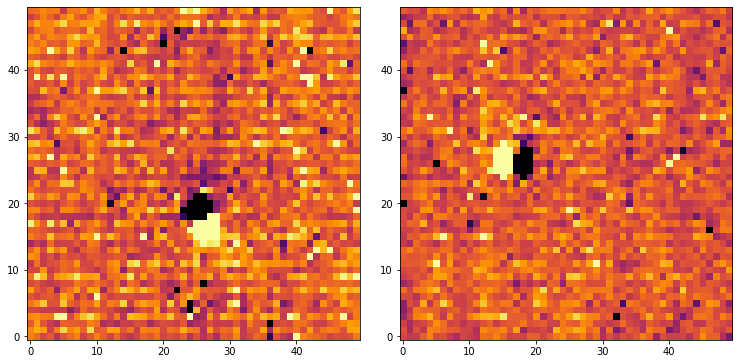

Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


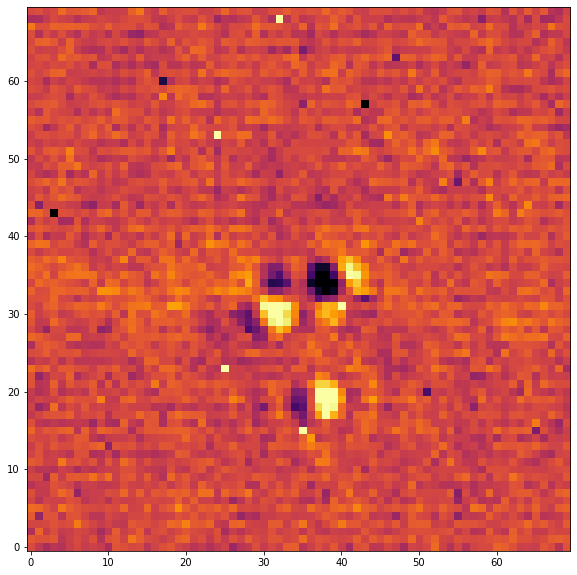

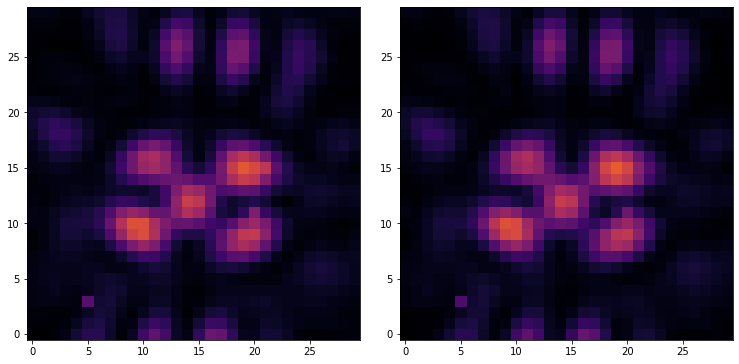

In [2]:
################
#### F1140C ####
################

# TA analysis

if True:
    path_TA_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs001/TA/'
    path_TA_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs002/TA/'

    TA_1 ,header_TA_1   = imp.load_cube(path_TA_1,'cal')
    TA_2 ,header_TA_2   = imp.load_cube(path_TA_2,'cal')

    diff_TA_pos1 = ndimage.shift(imp.clean_image_nan(TA_1[0]),[-0.12,0.05])-imp.clean_image_nan(TA_2[0])
    diff_TA_pos2 = ndimage.shift(imp.clean_image_nan(TA_1[1]),[-0.01,-0.02])-imp.clean_image_nan(TA_2[1])

    vm=100
    fig1,[sub4,sub5] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    tmp4 = sub4.imshow(diff_TA_pos1[150:200,150:200],origin='lower',cmap='inferno',interpolation='none',vmin=vm*-1,vmax=vm)
    tmp5 = sub5.imshow(diff_TA_pos2[100:150,120:170],origin='lower',cmap='inferno',interpolation='none',vmin=vm*-1,vmax=vm)
    plt.show()



path_SCI_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs001/'
path_SCI_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs002/'
path_bkg    = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs003/'

SCI_1 ,header_SCI_1   = imp.load_cube(path_SCI_1,'cal')
SCI_2 ,header_SCI_2   = imp.load_cube(path_SCI_2,'cal')
BKG = fits.open(glob.glob(path_bkg+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data

diff_SCI = ndimage.shift(imp.clean_image_nan(SCI_1-BKG),[-0.0,0.0])-imp.clean_image_nan(SCI_2-BKG)

vm=0.7
plt.figure(figsize=(10,10))
plt.imshow(diff_SCI[80:150,85:155],origin='lower',cmap='inferno',interpolation='none',vmin=vm*-1,vmax=vm)
plt.show()


fig1,[sub4,sub5] = plt.subplots(nrows=1,ncols=2,figsize=(10,8.5))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp4 = sub4.imshow((imp.clean_image_nan(SCI_1-BKG))[100:130,105:135],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=30)
tmp5 = sub5.imshow((imp.clean_image_nan(SCI_2-BKG))[100:130,105:135],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=30)
plt.show()

In [3]:
#########################
#### POST PROCESSING ####
#########################



path_save = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/TWA7/'

if not os.path.exists(path_save):
    os.makedirs(path_save)

pixscale = 0.110 # arcsec
filt='F1140C'

if filt == 'F1065C':
    lam = 10.65e-6    # lambda en m
    x0  = 120.25
    y0  = 112.03

if filt == 'F1140C':
    lam = 11.40e-6    # lambda en m
    x0  = 119.77
    y0  = 112.16

if filt == 'F1550C':
    lam = 15.50e-6    # lambda en m
    x0  = 119.71
    y0  = 113.28


aff  = 'cal'

path_tar_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs001/'
path_tar_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs002/'
path_ref    = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs004/'


path_bkg_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs003/'
path_bkg_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs005/'

cube_tar_1 ,header_tar_1   = imp.load_cube(path_tar_1,aff)
cube_tar_2 ,header_tar_2   = imp.load_cube(path_tar_2,aff)
cube_ref  ,header_ref      = imp.load_cube(path_ref,aff)

min_bkg_1 = fits.open(glob.glob(path_bkg_1+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data
min_bkg_2 = fits.open(glob.glob(path_bkg_2+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data
        
#bkg subtraction
cube_tar_1 = cube_tar_1-min_bkg_1
cube_tar_2 = cube_tar_2-min_bkg_1
cube_ref   = cube_ref-min_bkg_2

if True:
    ### write SCI and REF fits after minimum bkg subtraction  
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_tar_1[0]),fits.ImageHDU(data=cube_tar_1,header=header_tar_1[0])])
    hdu_list.writeto(path_save+'TWA7_roll-1_dither1_minimum_bkg_cal.fits',overwrite=True)

    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_tar_2[0]),fits.ImageHDU(data=cube_tar_2,header=header_tar_2[0])])
    hdu_list.writeto(path_save+'TWA7_roll-2_dither1_minimum_bkg_cal.fits',overwrite=True)

    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_ref[0][0]),fits.ImageHDU(data=cube_ref,header=header_ref[0][1])])
    hdu_list.writeto(path_save+'REF_CD23_9765_dither1-9_minimum_bkg_cal.fits',overwrite=True)

clipval = 3.
cube_tar_1  = imp.sigma_clip_jwst(cube_tar_1,clipval)
cube_tar_2  = imp.sigma_clip_jwst(cube_tar_2,clipval)
cube_ref    = imp.sigma_clip_jwst(cube_ref,clipval)

cube_tar_1 = imp.clean_image_nan(cube_tar_1)
cube_tar_2 = imp.clean_image_nan(cube_tar_2)
cube_ref = imp.clean_image_nan(cube_ref)

#resize
newd = 200
xd = np.shape(cube_tar_1)[1]
yd = np.shape(cube_tar_1)[0]
scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]

cube_tar_1 = ndimage.shift(cube_tar_1,[newd//2-y0,newd//2-x0])
cube_tar_2 = ndimage.shift(cube_tar_2,[newd//2-y0,newd//2-x0])
for i in range(len(cube_ref)): cube_ref[i,:,:]   = ndimage.shift(cube_ref[i,:,:],[newd//2-y0,newd//2-x0])
y0 = newd//2
x0 = newd//2

cube_tar_1 = cube_tar_1[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
cube_tar_2 = cube_tar_2[y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]
cube_ref   = cube_ref[:,y0-newd//2:y0+newd//2,x0-newd//2:x0+newd//2]

#PCA
PCA_1140_1 = imp.sub_PCA(cube_tar_1, cube_ref, [newd//2,newd//2], 2, dim=newd//2, plot=False)
PCA_1140_2 = imp.sub_PCA(cube_tar_2, cube_ref, [newd//2,newd//2], 2, dim=newd//2, plot=False)

# RDI
f_scale_1 = imp.flux_scaling_ta(path_tar_1+'TA', path_ref+'TA', aff, lam)
f_scale_2 = imp.flux_scaling_ta(path_tar_2+'TA', path_ref+'TA', aff, lam)
print("f_scale_1 with TA : ",f_scale_1)
print("f_scale_2 with TA : ",f_scale_2)

#perform RDI with 1 roll and 1 reference
RDI_1140_1 = imp.RDI_classic(cube_tar_1, cube_ref, f_scale=f_scale_1)
RDI_1140_2 = imp.RDI_classic(cube_tar_2, cube_ref, f_scale=f_scale_2)

#rotation
PA_V3_1 = header_tar_1[1]['PA_V3']     # 59.58852013851359
V3i_1   = header_tar_1[1]['V3I_YANG']  # 4.83544897
PA_V3_2 = header_tar_2[1]['PA_V3']     # 66.59658743620635
V3i_2   = header_tar_2[1]['V3I_YANG']  # 4.83544897

PCA_1140_1_r = ndimage.rotate(PCA_1140_1, -(PA_V3_1+V3i_1), reshape=False)
PCA_1140_2_r = ndimage.rotate(PCA_1140_2, -(PA_V3_2+V3i_2), reshape=False)
RDI_1140_1_c = np.copy(RDI_1140_1)
RDI_1140_2_c = np.copy(RDI_1140_2)
RDI_1140_1_c = imp.clean_image_nan(RDI_1140_1_c)
RDI_1140_2_c = imp.clean_image_nan(RDI_1140_2_c)
RDI_1140_1_r = ndimage.rotate(RDI_1140_1_c, -(PA_V3_1+V3i_1), reshape=False)
RDI_1140_2_r = ndimage.rotate(RDI_1140_2_c, -(PA_V3_2+V3i_2), reshape=False)

PCA_1140_t = (PCA_1140_1+PCA_1140_2)/2.
PCA_1140_t_r = (PCA_1140_1_r+PCA_1140_2_r)/2.
RDI_1140_t = (RDI_1140_1+RDI_1140_2)/2.
RDI_1140_t_r = (RDI_1140_1_r+RDI_1140_2_r)/2.

imp.save_fits(RDI_1140_1,path_save+'RDI_1140_roll_1.fits')
imp.save_fits(RDI_1140_2,path_save+'RDI_1140_roll_2.fits')
imp.save_fits(RDI_1140_t,path_save+'RDI_1140_somme_roll.fits')
imp.save_fits(RDI_1140_1_r,path_save+'RDI_1140_roll_1_rot.fits')
imp.save_fits(RDI_1140_2_r,path_save+'RDI_1140_roll_2_rot.fits')
imp.save_fits(RDI_1140_t_r,path_save+'RDI_1140_somme_roll_rot.fits')

imp.save_fits(PCA_1140_1,path_save+'PCA_1140_roll_1.fits')
imp.save_fits(PCA_1140_2,path_save+'PCA_1140_roll_2.fits')
imp.save_fits(PCA_1140_t,path_save+'PCA_1140_somme_roll.fits')
imp.save_fits(PCA_1140_1_r,path_save+'PCA_1140_roll_1_rot.fits')
imp.save_fits(PCA_1140_2_r,path_save+'PCA_1140_roll_2_rot.fits')
imp.save_fits(PCA_1140_t_r,path_save+'PCA_1140_somme_roll_rot.fits')

imp.save_fits(cube_tar_1,path_save+'cube_1140_pixelcorr_1.fits')
imp.save_fits(cube_tar_2,path_save+'cube_1140_pixelcorr_2.fits')

imp.save_fits(RDI_1140_1_c,path_save+'RDI_1140_roll_1_clean.fits')
imp.save_fits(RDI_1140_2_c,path_save+'RDI_1140_roll_2_clean.fits')
imp.save_fits(imp.clean_image_nan(cube_tar_1),path_save+'cube_1140_pixelcorr_1_clean.fits')
imp.save_fits(imp.clean_image_nan(cube_tar_2),path_save+'cube_1140_pixelcorr_2_clean.fits')



Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 9 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  1.3965812874037857
156 156
Roll - TA 1
Result : A = 8878.1 / x0 = 155.86 / y0 = 155.64 / width_x = 1.4 / width_y = 1.47
Stddev : A = 70.7 / x0 = 0.01 / y0 = 0.01 / width_x = 0.01 / width_y = 0.01
115 117
Roll - TA 2
Result : A = 8976.6 / x0 = 116.63 / y0 = 114.57 / width_x = 1.39 / width_y = 1.45
Stddev : A = 65.6 / x0 = 0.01 / y0 = 0.01 / width_x = 0.01 / width_y = 0.01
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
155 156
Ref - TA 1
Result : A = 18945.6 / x0 = 155.99 / y0 = 154.89 / width_x = 1.37 / width_y = 1.43
Stddev : A = 57.4 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
115 117
Ref - TA 2
Result : A = 18956.2 / x0 = 116.66 / y0 = 114.6 / width_x = 1.37 / width_y = 1.43
Stddev : A = 53.2 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Numbe

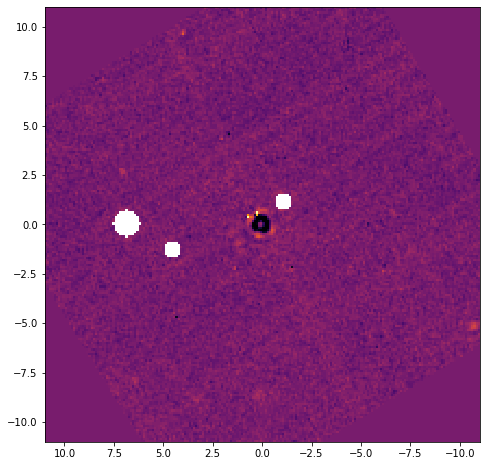

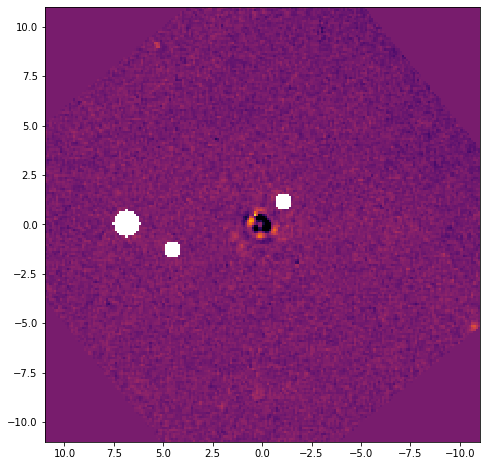

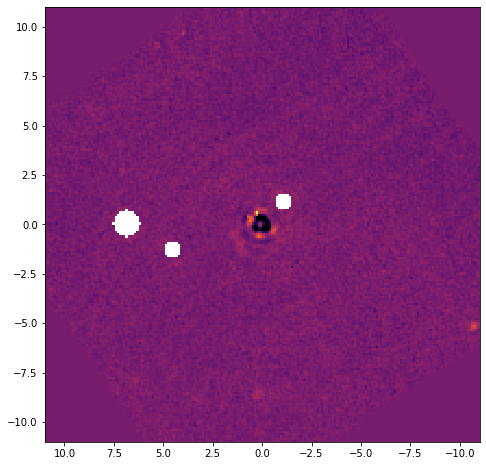

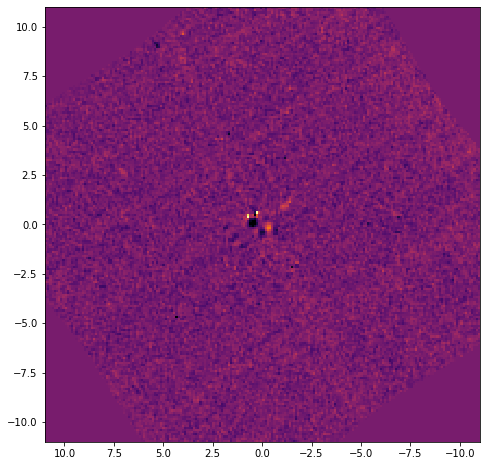

0.000 1.164e-17 1.203e-17
0.110 3.691e-18 3.175e-18
0.220 2.243e-18 1.358e-18
0.330 1.678e-18 8.015e-19
0.440 1.289e-18 5.994e-19
0.550 9.213e-19 5.011e-19
0.660 6.254e-19 4.020e-19
0.770 3.858e-19 2.625e-19
0.880 2.453e-19 1.653e-19
0.990 1.740e-19 1.172e-19
1.100 1.182e-19 8.251e-20
1.210 8.802e-20 6.457e-20
1.320 7.279e-20 5.561e-20
1.430 6.101e-20 4.783e-20
1.540 5.720e-20 4.566e-20
1.650 5.527e-20 4.495e-20
1.760 5.192e-20 4.332e-20
1.870 4.921e-20 4.238e-20
1.980 4.492e-20 3.991e-20
2.090 4.194e-20 3.815e-20
2.200 4.164e-20 3.844e-20
2.310 4.048e-20 3.772e-20
2.420 3.954e-20 3.710e-20
2.530 3.955e-20 3.731e-20
2.640 3.931e-20 3.722e-20
2.750 3.841e-20 3.647e-20
2.860 3.830e-20 3.649e-20
2.970 3.767e-20 3.610e-20
3.080 3.623e-20 3.496e-20
3.190 3.561e-20 3.458e-20
3.300 3.522e-20 3.434e-20
3.410 3.467e-20 3.386e-20
3.520 3.433e-20 3.354e-20
3.630 3.468e-20 3.389e-20
3.740 3.455e-20 3.379e-20
3.850 3.434e-20 3.363e-20
3.960 3.380e-20 3.312e-20
4.070 3.387e-20 3.318e-20
4.180 3.394e

In [4]:
image_red = "PCA" #"RDI"

if image_red == "RDI":
    image1  = RDI_1140_1_c.copy()  # roll 1 RDI
    image2  = RDI_1140_2_c.copy()  # roll 2 RDI
if image_red == "PCA":
    image1  = PCA_1140_1_r.copy()  # roll 1 PCA
    image2  = PCA_1140_2_r.copy()  # roll 2 PCA

ydim = np.shape(image1)[-2]
xdim = np.shape(image1)[-1]
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

x0=xdim//2
y0=ydim//2


# transmission
path_transmission = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327/'
transmi_sum = fits.open(path_transmission+'transmi_sum.fits')[0].data
transmi_max = fits.open(path_transmission+'transmi_max.fits')[0].data


### Transmission à 45° (optimale)

t_sum_45 = transmi_sum.copy()
t_sum_45[np.where(np.isnan(t_sum_45))] = 0
t_sum_45 = ndimage.rotate(t_sum_45, 45.-V3i_1, reshape=False)
t_sum_45 = t_sum_45[xdim//2,:]
t_sum_45 = (t_sum_45[xdim//2:]+t_sum_45[0:xdim//2][::-1])/2.

t_max_45 = transmi_max.copy()
t_max_45[np.where(np.isnan(t_max_45))] = 0
t_max_45 = ndimage.rotate(t_max_45, 45.-V3i_1, reshape=False)
t_max_45 = t_max_45[xdim//2,:]
t_max_45 = (t_max_45[xdim//2:]+t_max_45[0:xdim//2][::-1])/2.


### Transmission à 15° (pas optimale)

t_sum_5 = transmi_sum.copy()
t_sum_5[np.where(np.isnan(t_sum_5))] = 0
t_sum_5 = ndimage.rotate(t_sum_5, 15.-V3i_1, reshape=False)
t_sum_5 = t_sum_5[xdim//2,:]
t_sum_5 = (t_sum_5[xdim//2:]+t_sum_5[0:xdim//2][::-1])/2.

t_max_5 = transmi_max.copy()
t_max_5[np.where(np.isnan(t_max_5))] = 0
t_max_5 = ndimage.rotate(t_max_5, 15.-V3i_1, reshape=False)
t_max_5 = t_max_5[xdim//2,:]
t_max_5 = (t_max_5[xdim//2:]+t_max_5[0:xdim//2][::-1])/2.


dr = 1.5*lam/6.5*180.*3600./np.pi/pixscale #pour faire une zone de 1,5*2 = 3 L/D de diametre
Y, X = np.ogrid[:ydim, :xdim]

#### masks for background objects (galaxies, stars)
mask_pla = np.sqrt((X - x0-9)**2 + (Y-y0-10)**2) > dr
mask_gal = np.sqrt((X - x0+63)**2 + (Y-y0)**2) > 6
mask_gal2 = np.sqrt((X - x0+42)**2 + (Y-y0+12)**2) > dr

mask_bkg_obj = mask_pla*mask_gal*mask_gal2

if image_red == "RDI":
    image2 = ndimage.rotate(image2, (PA_V3_1-PA_V3_2), reshape=False)

### supprimer manuellement les pixels mort restant 
pixel_mort=[[83,115],[81,113],[81,112],[80,86],[58,60]]
for i in pixel_mort:
    image1[i[0],i[1]] = math.nan
    image2[i[0],i[1]] = math.nan
imp.clean_image_nan(image1)
imp.clean_image_nan(image2)
    
sum_img  = (image1+image2)/2.
diff_img = (image1-image2)

sum_img[np.where(mask_bkg_obj == 0)] = math.nan
image1[np.where(mask_bkg_obj == 0)] = math.nan
image2[np.where(mask_bkg_obj == 0)] = math.nan


plt.figure(figsize=(8,8))
plt.imshow(image1,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(image2,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(sum_img,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(diff_img,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()


mask_pla = np.sqrt((X - x0 +0.5)**2 + (Y-y0+0.5)**2)

### Std dev azimutale dans un anneau de 3 L/D de largeur
std_1    = np.ndarray(xdim//2)
std_2    = np.ndarray(xdim//2) ### pour roll 2
std_sum  = np.ndarray(xdim//2) ### pour sum
std_map_1 = np.ndarray([xdim,xdim])*0.
std_map_2 = np.ndarray([xdim,xdim])*0.
mask_map = np.ndarray([xdim//2,xdim,xdim])*0.
for i in range(0,xdim//2):
    mask_sel  = (mask_pla >= i-dr) * (mask_pla < i+dr)
    mask_map[i,:,:] = mask_sel*sum_img
    std_1[i]    = np.nanstd(image1[mask_sel])  ### radial pour roll 1
    std_2[i]    = np.nanstd(image2[mask_sel])  ### radial pour roll 2
    std_sum[i]  = np.nanstd(sum_img[mask_sel]) ### radial pour sum
    std_map_1[mask_sel] = std_1[i]            ### MAP pour roll 1
    std_map_2[mask_sel] = std_2[i]            ### MAP pour roll 2

imp.save_fits(mask_map,path_save+'mask_map.fits')
imp.save_fits(mask_pla,path_save+'mask_pla.fits')


### Std dev local dans 3 L/D pour chaque pixel hors bords sur 2 pixels
std_psf_1   = np.ndarray([ydim,xdim]) ### Roll 1
std_psf_2   = np.ndarray([ydim,xdim]) ### Roll 2
std_psf_sum = np.ndarray([ydim,xdim]) ### Sum Roll
for i in range(ydim):
    for j in range(xdim):
        if (i < 2) or (j < 2) or (i > ydim-3) or (j > xdim-3):
            std_psf_1[i,j] = 0.
            std_psf_2[i,j] = 0.
            std_psf_sum[i,j] = 0.
        else:
            mask_psf = np.sqrt((X - xdim+j)**2 + (Y - ydim+i)**2) <= dr
            std_psf_1[i,j] = np.nanstd(image1[mask_psf])
            std_psf_2[i,j] = np.nanstd(image2[mask_psf])
            std_psf_sum[i,j] = np.nanstd(sum_img[mask_psf])
    
    
    
### Calcul pour passer de 1 Sr de surface a 1 pixel de surface
# 1 pixel = pixscale**2 in arcsec
# 1 radian = 3600*180/pi arcsec
# 1 sr = radian**2
# 1 pixel in sr = (pixscale/(3600*180/np.pi))**2
#print("1 pixel in sr = ",(pixscale/(3600*180/np.pi))**2)
pixtosr = (pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
mjytoujy = 1e12                          #Mjy to µjy
nbpixel = np.pi*dr**2                    #nombre de pixel dans la zone de photométrie de "dr" l/D de rayon 
coef=pixtosr*mjytoujy*np.sqrt(nbpixel)*2.25745 # 2,257784785 facteur de correction d'ouverture obtenu avec STPSF : flux in 1.5L/D : 0.25375 ; flux in the image : 0.57283 : 0.57283/0.25375 = 2.25745


### passage de µJy a W/m2/µm (les flux sont en MJy/sr mais le facteur de conversion est linéaire et donc peut être fait plus tard)
std_1_wm   = flux_uJy_to_Wm(11.4,std_1)
std_2_wm   = flux_uJy_to_Wm(11.4,std_2)
std_sum_wm = flux_uJy_to_Wm(11.4,std_sum)

### map 5 Sigma std dev en microjy par pixel avec correction de la transmission (profil radial / transmission)
imp.save_fits(5*coef*std_map_1/transmi_max,path_save+'TWA7_std_ujy_roll1_transmi_max.fits')
imp.save_fits(5*coef*std_map_1/transmi_sum,path_save+'TWA7_std_ujy_roll1_transmi_sum.fits')
imp.save_fits(5*coef*std_map_2/transmi_max,path_save+'TWA7_std_ujy_roll2_transmi_max.fits')
imp.save_fits(5*coef*std_map_2/transmi_sum,path_save+'TWA7_std_ujy_roll2_transmi_sum.fits')

### pareil mais en W.m-2 par pixel
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_map_1)/transmi_max,path_save+'TWA7_map_std_wm2_roll1_transmi_max.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_map_1)/transmi_sum,path_save+'TWA7_map_std_wm2_roll1_transmi_sum.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_map_2)/transmi_max,path_save+'TWA7_map_std_wm2_roll2_transmi_max.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_map_2)/transmi_sum,path_save+'TWA7_map_std_wm2_roll2_transmi_sum.fits')

### 5 sigmae std dev avec zone de 3 L/D conlissante sur chaque pixel (c'est pas ouf) corrigé de la transmission
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_psf_1)/transmi_max,path_save+'TWA7_std_wm2_roll1_transmi_max.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_psf_1)/transmi_sum,path_save+'TWA7_std_wm2_roll1_transmi_sum.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_psf_2)/transmi_max,path_save+'TWA7_std_wm2_roll2_transmi_max.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_psf_2)/transmi_sum,path_save+'TWA7_std_wm2_roll2_transmi_sum.fits')
imp.save_fits((flux_uJy_to_Wm(11.4,std_psf_sum)*coef*5)/transmi_sum*mask_bkg_obj,path_save+'TWA7_std_psf_wm2_transmi_sum.fits')
imp.save_fits((flux_uJy_to_Wm(11.4,std_psf_sum)*coef*5)/transmi_max*mask_bkg_obj,path_save+'TWA7_std_psf_wm2_transmi_max.fits')

lim_det_5sig_t15_wm = np.ndarray(xdim//2)
lim_det_5sig_t45_wm = np.ndarray(xdim//2)
for i in range(0,xdim//2):
    #print("{:4.3f}".format((i+0.5)*0.11),"{:4.3f}".format(coef*std_m2[i]),"{:.3e}".format(coef*std_m2_wm[i]))
    lim_det_5sig_t15_wm[i] = 5*coef*std_sum_wm[i]/t_sum_5[i]
    lim_det_5sig_t45_wm[i] = 5*coef*std_sum_wm[i]/t_sum_45[i]
    print("{:4.3f}".format(i*0.11),"{:.3e}".format(lim_det_5sig_t15_wm[i]),"{:.3e}".format(lim_det_5sig_t45_wm[i]))

    

In [5]:
saveformat = "png"

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*std_map_1/transmi_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [µJy]')
fig1.savefig(path_save+'TWA7_std_ujy_roll1_transmi_max.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*std_map_2/transmi_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [µJy]')
fig1.savefig(path_save+'TWA7_std_ujy_roll2_transmi_sum.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)


fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*flux_uJy_to_Wm(11.4,std_map_1)/transmi_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [µJy]')
fig1.savefig(path_save+'TWA7_std_wm2_roll1_transmi_max.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*flux_uJy_to_Wm(11.4,std_map_2)/transmi_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [µJy]')
fig1.savefig(path_save+'TWA7_std_wm2_roll2_transmi_sum.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)



fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0.5,xdim//2,1)*0.11,std_1/std_2,'black',label='Ratio Std Dev roll 1/2')
plt.title('Ratio Std Dev')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'Ratio')
plt.ylim([0,3])
plt.grid()
plt.legend()
fig1.savefig(path_save+'TWA7_ratio_stddev.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_1/t_sum_5,'green',label='Roll 1 - 15°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_2/t_sum_5,'blue',label='Roll 2 - 15°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_sum/t_sum_45,'red',label='Mean - 45°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_sum/t_sum_5,'violet',label='Mean - 15°')
plt.title(r'Std Dev - 5$\sigma$')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'5$\sigma$ Detection limit [µJy]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.grid(True, which="major", ls="-")
plt.grid(True, which="minor", ls="--")
plt.ylim([1e1,1e4])
plt.xlim([0,8])
plt.legend()
fig1.savefig(path_save+'TWA7_stddev_ujy.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)




fig1 = plt.figure(figsize=(10,7))
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_1_wm/t_sum_5,'green',label='Roll 1 - 15°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_2_wm/t_sum_5,'blue',label='Roll 2 - 15°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_sum_wm/t_sum_45,'red',label='Mean - 45°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_sum_wm/t_sum_5,'violet',label='Mean - 15°')
plt.title(r'Std Dev - 5$\sigma$')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.grid(True, which="major", ls="-")
plt.grid(True, which="minor", ls="--")
plt.ylim([1e-21,1e-17])
plt.xlim([0,4.5])
plt.legend()
fig1.savefig(path_save+'TWA7_stddev_wm2.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)


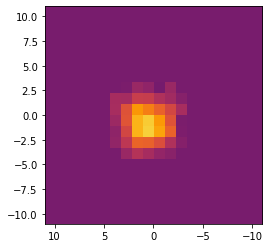

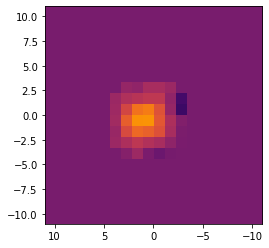

img 1 flux in w/m2/µm :  1.7758661903323118e-19
img 1 std dev 1 sigma at 1.54 :  8.908304908274808e-21
img 1 SNR :  45.002154423810026
img 2 flux in w/m2/µm :  1.289590543086819e-19
img 2 std dev 1 sigma at 1.54 :  8.908304908274808e-21
img 2 SNR :  32.67946260783212
img tot flux in w/m2/µm :  1.289590543086819e-19
img tot std dev 1 sigma at 1.54 :  8.908304908274808e-21
img tot SNR :  38.36628500884201


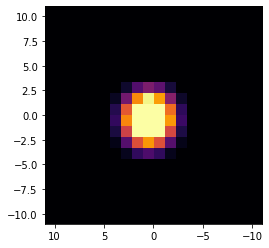

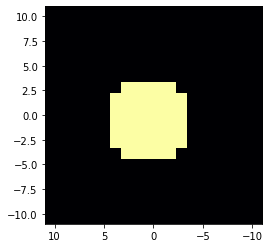

flux STPSF in 1.5L/D radius :  0.2537478720814958
flux STPSF in 3.5L/D radius :  0.402465222065554
flux STPSF in the whole image :  0.5728274333175479


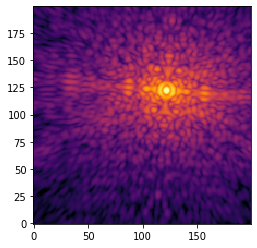

flux STPSF in 1.5L/D radius :  0.44297437120269706
flux STPSF in 3.5L/D radius :  0.7025941822210995
flux STPSF in the whole image :  0.9999999999999999


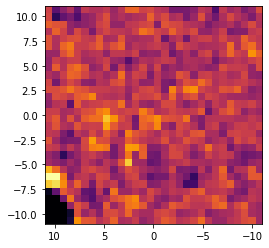

img 1 flux STPSF norm in 1.5L/D radius :  2.243651144663411e-19


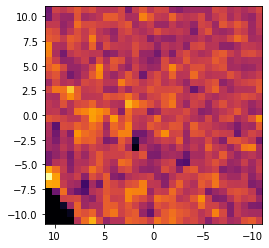

img 2 flux STPSF norm in 1.5L/D radius :  1.6798756338108928e-19


In [188]:
### limite de detection avec fausse planète STPSF

image_red = "PCA" #"RDI"

if image_red == "RDI":
    image1  = RDI_1140_1_c.copy()  # roll 1 RDI
    image2  = RDI_1140_2_c.copy()  # roll 2 RDI
if image_red == "PCA":
    image1  = PCA_1140_1_r.copy()  # roll 1 PCA
    image2  = PCA_1140_2_r.copy()  # roll 2 PCA
    image_t = (image1+image2)/2.

ydim = np.shape(image1)[-2]
xdim = np.shape(image1)[-1]
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

x0=xdim//2
y0=ydim//2

stpsf = fits.open('/home/cperrot/Work/raw/JWST/STPSF/F1140C_PSF/F1140C_PSF_2500_2500mas.fits')[0].data

pixtosr = (pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
mjytoujy = 1e12 #Mjy to µjy
coef_f=pixtosr*mjytoujy

# transmission
path_transmission = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327/'
transmi_sum = fits.open(path_transmission+'transmi_sum.fits')[0].data
transmi_img1=transmi_sum[87,103] #position of the planet in roll 1
transmi_img2=transmi_sum[87,102] #position of the planet in roll 2

dr = 1*lam/6.5*180.*3600./np.pi/pixscale
Y, X = np.ogrid[:ydim, :xdim]

#calcul SNR
mask_pla = np.sqrt((X - x0-9)**2 + (Y-y0-9)**2) < 1.5*dr
plt.imshow((image1*mask_pla)[x0-0:x0+20,y0-0:y0+20],origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.imshow((image2*mask_pla)[x0-0:x0+20,y0-0:y0+20],origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()

flux_pla1 = np.sum((image1*mask_pla)[np.where(image1 >= -0)])
flux_pla1_wm   = flux_uJy_to_Wm(11.4,coef_f*flux_pla1)

flux_pla2 = np.sum((image2*mask_pla)[np.where(image2 >= -0)])
flux_pla2_wm   = flux_uJy_to_Wm(11.4,coef_f*flux_pla2)

flux_pla_t = np.sum((image_t*mask_pla)[np.where(image_t >= -0)])
flux_pla_t_wm   = flux_uJy_to_Wm(11.4,coef_f*flux_pla_t)


sep_i = 14

print('img 1 flux in w/m2/µm : ',flux_pla1_wm)
print('img 1 std dev 1 sigma at 1.54'' : ',coef*std_sum_wm[sep_i])
print('img 1 SNR : ',flux_pla1_wm/(coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i]))
print('img 2 flux in w/m2/µm : ',flux_pla2_wm)
print('img 2 std dev 1 sigma at 1.54'' : ',coef*std_sum_wm[sep_i])
print('img 2 SNR : ',flux_pla2_wm/(coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i]))
print('img tot flux in w/m2/µm : ',flux_pla2_wm)
print('img tot std dev 1 sigma at 1.54'' : ',coef*std_sum_wm[sep_i])
print('img tot SNR : ',flux_pla_t_wm/(coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i]))



mask_psf  = np.sqrt((X - x0-22)**2 + (Y-y0-22)**2) < 1.5*dr
mask_psf2 = np.sqrt((X - x0-22)**2 + (Y-y0-22)**2) < 3.5*dr

plt.imshow((stpsf*mask_psf)[x0+round(2.5/pixscale)-10:x0+round(2.5/pixscale)+10,y0+round(2.5/pixscale)-10:y0+round(2.5/pixscale)+10],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=0.01,extent=scale)
plt.show()
plt.imshow((mask_psf)[x0+round(2.5/pixscale)-10:x0+round(2.5/pixscale)+10,y0+round(2.5/pixscale)-10:y0+round(2.5/pixscale)+10],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=0.01,extent=scale)
plt.show()
#[x0+round(2.5/pixscale)-5:x0+round(2.5/pixscale)+5,y0+round(2.5/pixscale)-5:y0+round(2.5/pixscale)+5]

print('flux STPSF in 1.5L/D radius : ',np.sum(stpsf[mask_psf]))
print('flux STPSF in 3.5L/D radius : ',np.sum(stpsf[mask_psf2]))
print('flux STPSF in the whole image : ',np.sum(stpsf))

plt.imshow((stpsf),origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(vmin=1e-8, vmax=1e-2))#,vmin=0,vmax=0.01,extent=scale)
plt.show()


norm = np.sum(stpsf)
stpsf /= norm


print('flux STPSF in 1.5L/D radius : ',np.sum(stpsf[mask_psf]))
print('flux STPSF in 3.5L/D radius : ',np.sum(stpsf[mask_psf2]))
print('flux STPSF in the whole image : ',np.sum(stpsf))

plt.imshow((image1-ndimage.shift(stpsf*57,[-13.5,-13.2]))[x0-0:x0+30,y0-0:y0+30],origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
plt.show()
print('img 1 flux STPSF norm in 1.5L/D radius : ',flux_uJy_to_Wm(11.4,coef_f*np.sum(57*stpsf[mask_psf]))/transmi_img1)

plt.imshow((image2-ndimage.shift(stpsf*40,[-13,-13.5]))[x0-0:x0+30,y0-0:y0+30],origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
plt.show()
print('img 2 flux STPSF norm in 1.5L/D radius : ',flux_uJy_to_Wm(11.4,coef_f*np.sum(40*stpsf[mask_psf]))/transmi_img2)

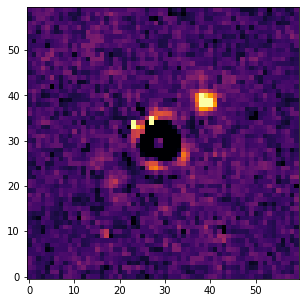

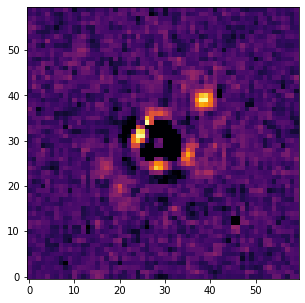

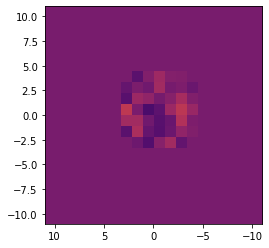

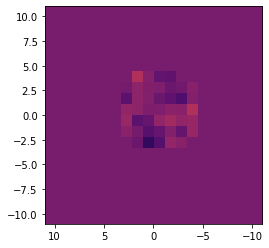

img 1 flux in w/m2/µm :  1.7912003186623096e-20
img 1 std dev 1 sigma at 1.54 :  3.946180384183396e-21
img 1 SNR :  4.539073595929833
img 2 flux in w/m2/µm :  1.3673341916511553e-20
img 2 std dev 1 sigma at 1.54 :  3.946180384183396e-21
img 2 SNR :  3.464956131076874
Flux en MJy/sr :  0.0
Lim det en W/m2/µm :  0.0
Flux en MJy/sr :  0.0
Lim det en W/m2/µm :  0.0


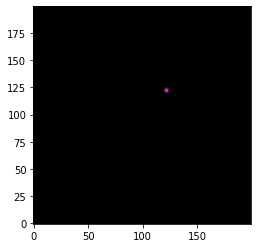

In [191]:
if image_red == "PCA":
    image1  = PCA_1140_1_r.copy()  # roll 1 PCA rotated
    image2  = PCA_1140_2_r.copy()  # roll 2 PCA rotated

image = (image1+image2)/2.
    
stpsf_cen = ndimage.shift(stpsf,[-22.62,-22.5])

if False:
    plt.figure(figsize=(4,4))
    plt.imshow(stpsf_cen[x0-10:x0+10,y0-10:y0+10],origin='lower',cmap='inferno',interpolation='none',vmin=-0.025,vmax=0.032) 
    plt.show()


sep_i = 14

fake_pla = ndimage.shift(stpsf_cen,[0.94*sep_i/np.sqrt(2),0.95*sep_i/np.sqrt(2)]) #for negative fake planet 
fake_pla = ndimage.shift(stpsf_cen,[1.0*sep_i/np.sqrt(2),-1.0*sep_i/np.sqrt(2)])

nsig = 0.#45.
a1 = nsig*std_sum[sep_i]*coef/coef_f #pour prendre en compte l'impact du la taille de la psf où la mesure est faite

dx=30

plt.figure(figsize=(5,5))
plt.imshow((image1+fake_pla*a1)[x0-dx:x0+dx,y0-dx:y0+dx],origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=1.3) #[x0-9:x0+11,y0-9:y0+11]
plt.show()

fake_pla = ndimage.shift(stpsf_cen,[0.95*sep_i/np.sqrt(2),0.92*sep_i/np.sqrt(2)]) #for negative fake planet 
fake_pla = ndimage.shift(stpsf_cen,[1.0*sep_i/np.sqrt(2),-1.0*sep_i/np.sqrt(2)])

nsig = 0.#32.6
a2 = nsig*std_sum[sep_i]*coef/coef_f #pour prendre en compte l'impact du la taille de la psf où la mesure est faite

plt.figure(figsize=(5,5))
plt.imshow((image2+fake_pla*a2)[x0-dx:x0+dx,y0-dx:y0+dx],origin='lower',cmap='inferno',interpolation='none',vmin=-0.3,vmax=1.3) #[x0-9:x0+11,y0-9:y0+11]
plt.show()



#calcul SNR
mask_pla = np.sqrt((X - x0+10)**2 + (Y-y0-10)**2) < 1.5*dr
plt.imshow(((image1+fake_pla*a1)*mask_pla)[x0-0:x0+20,y0-20:y0+0],origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=1,extent=scale)
plt.show()
plt.imshow(((image2+fake_pla*a2)*mask_pla)[x0-0:x0+20,y0-20:y0+0],origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=1,extent=scale)
plt.show()

flux_pla1 = np.sum(((image1+fake_pla*a1)*mask_pla)[np.where((image1+fake_pla*a1) >= -0)])
flux_pla1_wm   = flux_uJy_to_Wm(11.4,coef_f*flux_pla1)

flux_pla2 = np.sum(((image2+fake_pla*a2)*mask_pla)[np.where((image2+fake_pla*a2) >= -0)])
flux_pla2_wm   = flux_uJy_to_Wm(11.4,coef_f*flux_pla2)

sep_i = 14

print('img 1 flux in w/m2/µm : ',flux_pla1_wm)
print('img 1 std dev 1 sigma at 1.54'' : ',coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i])
print('img 1 SNR : ',flux_pla1_wm/(coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i]))
print('img 2 flux in w/m2/µm : ',flux_pla2_wm)
print('img 2 std dev 1 sigma at 1.54'' : ',coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i])
print('img 2 SNR : ',flux_pla2_wm/(coef_f*np.sqrt(nbpixel)*std_sum_wm[sep_i]))








print('Flux en MJy/sr : ',a1)
print('Lim det en W/m2/µm : ',flux_uJy_to_Wm(11.4,a1*coef_f)/t_sum_45[sep_i])

print('Flux en MJy/sr : ',a2)
print('Lim det en W/m2/µm : ',flux_uJy_to_Wm(11.4,a2*coef_f)/t_sum_45[sep_i])


plt.figure(figsize=(4,4))
plt.imshow(stpsf*mask_psf,origin='lower',cmap='inferno',interpolation='none',vmin=-0,vmax=0.05) 
plt.show()

In [56]:
np.sum(a*stpsf)/np.sum(a*stpsf[mask_psf])

2.257466943933914

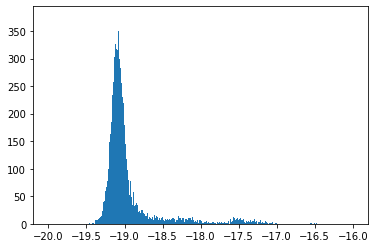

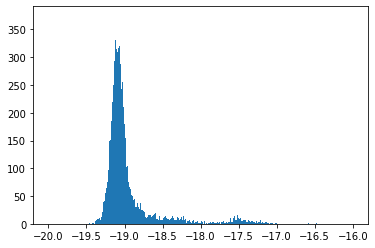

In [6]:
plt.hist(np.log10((flux_uJy_to_Wm(11.4,std_psf_sum)*coef*5)/transmi_sum).flatten(), bins=500, range=(-20,-16),log=False)
plt.show()
plt.hist(np.log10((flux_uJy_to_Wm(11.4,std_psf_sum)*coef*5)/transmi_max).flatten(), bins=500, range=(-20,-16),log=False)
plt.show()

In [96]:
dr = 1.5*lam/6.5*180.*3600./np.pi/pixscale
dr

3.772329611577911

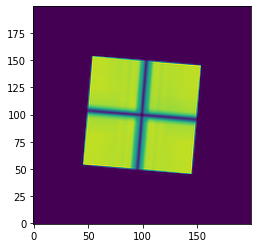

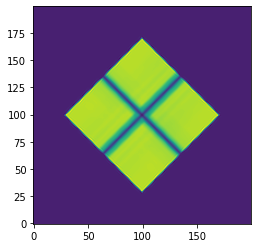

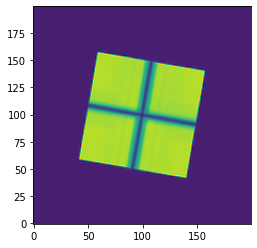

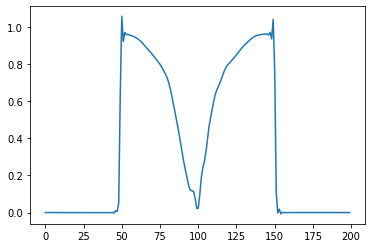

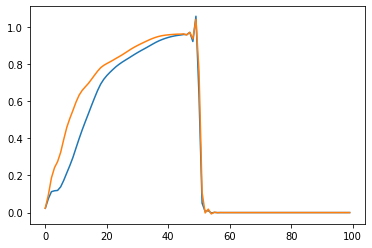

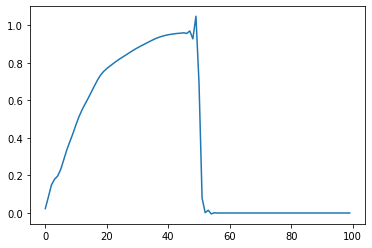

In [87]:
toto = transmi_sum.copy()

toto[np.where(np.isnan(toto))] = 0

plt.imshow(toto,origin='lower')
plt.show()

toto = ndimage.rotate(toto, 45.-V3i_1, reshape=False)
plt.imshow(toto,origin='lower')
plt.show()

toto = ndimage.rotate(toto, -45+10., reshape=False)
plt.imshow(toto,origin='lower')
plt.show()

plt.plot(np.arange(0,xdim,1),toto[100,:])
plt.show()
tata = toto[100,:]

plt.plot(tata[0:100][::-1])
plt.plot(tata[100:])
plt.show()
plt.plot((tata[100:]+tata[0:100][::-1])/2.)
plt.show()